In [1]:
print("Customer Complaint Analytics Dashboard")
print("My data analytics project has started!")

Customer Complaint Analytics Dashboard
My data analytics project has started!


In [3]:
import pandas as pd

print("Pandas is working!")
print("Pandas version:", pd.__version__)

Pandas is working!
Pandas version: 3.0.6


In [5]:
import pandas as pd

file_path = r"C:\Users\nnpat\Downloads\complaints-2026-10-12_13_43.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (75989, 15)


,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2024-01-01T01:53:02.000Z,Credit card,General-purpose credit card or charge card,Improper use of your report,Reporting company used your report improperly,NaN,CAPITAL ONE FINANCIAL CORPORATION,GA,31537,NaN,Web,2024-01-01T02:02:02.000Z,Closed with explanation,Yes,8085114
1,2024-01-01T06:23:49.000Z,Credit card,General-purpose credit card or charge card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,NaN,CAPITAL ONE FINANCIAL CORPORATION,CA,94538,NaN,Web,2024-01-01T07:09:13.000Z,Closed with explanation,Yes,8086913
2,2024-01-01T13:57:28.000Z,Credit card,Store credit card,Problem with a purchase shown on your statement,Credit card company isn't resolving a dispute ...,Company has responded to the consumer and the ...,SYNCHRONY FINANCIAL,NJ,076XX,NaN,Web,2024-01-10T15:35:28.000Z,Closed with explanation,Yes,8086654
3,2024-01-01T15:48:58.000Z,Credit card,General-purpose credit card or charge card,Problem with a company's investigation into an...,Problem with personal statement of dispute,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",IN,46235,NaN,Web,2024-01-01T16:12:17.000Z,Closed with explanation,Yes,8086469
4,2024-01-01T16:29:32.000Z,Credit card,Store credit card,Fees or interest,Problem with fees,NaN,TD BANK US HOLDING COMPANY,GA,30075,NaN,Web,2024-01-01T16:39:47.000Z,Closed with explanation,Yes,8086422


In [4]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset size: (75989, 15)

Column names:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 75989 entries, 0 to 75988
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Date received                 75989 non-null  str  
 1   Product                       75989 non-null  str  
 2   Sub-product                   75989 non-null  str  
 3   Issue                         75989 non-null  str  
 4   Sub-issue                     75926 non-null  str  
 5   Company public response       38472 non-null  str  
 6   Company                       75989 non-null  str  
 7   State                         75776 non-null  str  
 8   ZIP code              

In [5]:
# Find the 10 most common complaint issues

top_issues = df["Issue"].value_counts().head(10)

print("Top 10 Customer Complaint Issues:")
print(top_issues)

Top 10 Customer Complaint Issues:
Issue
Problem with a purchase shown on your statement                    14595
Incorrect information on your report                               13261
Problem with a company's investigation into an existing problem     9911
Getting a credit card                                               9683
Other features, terms, or problems                                  6769
Fees or interest                                                    6343
Closing your account                                                4273
Problem when making payments                                        4147
Advertising and marketing, including promotional offers             2766
Trouble using your card                                             2315
Name: count, dtype: int64


In [6]:
# Find the 10 companies with the most complaints

top_companies = df["Company"].value_counts().head(10)

print("Top 10 Companies by Complaint Count:")
print(top_companies)

Top 10 Companies by Complaint Count:
Company
TRANSUNION INTERMEDIATE HOLDINGS, INC.    7532
EQUIFAX, INC.                             7382
Experian Information Solutions Inc.       7097
CAPITAL ONE FINANCIAL CORPORATION         7058
CITIBANK, N.A.                            6685
SYNCHRONY FINANCIAL                       5301
JPMORGAN CHASE & CO.                      5276
AMERICAN EXPRESS COMPANY                  3950
BANK OF AMERICA, NATIONAL ASSOCIATION     3381
Bread Financial Holdings, Inc.            2515
Name: count, dtype: int64


In [7]:
# Count timely and untimely company responses

response_counts = df["Timely response?"].value_counts()

print("Company Response Timeliness:")
print(response_counts)

print("\nPercentage breakdown:")
print((df["Timely response?"].value_counts(normalize=True) * 100).round(2))

Company Response Timeliness:
Timely response?
Yes    75851
No       138
Name: count, dtype: int64

Percentage breakdown:
Timely response?
Yes    99.82
No      0.18
Name: proportion, dtype: float64


In [8]:
# Analyse complaints by financial product

product_counts = df["Product"].value_counts()

print("Complaints by Financial Product:")
print(product_counts)

Complaints by Financial Product:
Product
Credit card    75989
Name: count, dtype: int64


In [9]:
# Convert complaint dates into datetime format

df["Date received"] = pd.to_datetime(df["Date received"])

# Count complaints by month

monthly_complaints = (
    df.groupby(df["Date received"].dt.to_period("M"))
      .size()
)

print("Monthly Complaint Trends:")
print(monthly_complaints)

Monthly Complaint Trends:
Date received
2024-01    5247
2024-02    5182
2024-03    5889
2024-04    6676
2024-05    6760
2024-06    5535
2024-07    6192
2024-08    7355
2024-09    7185
2024-10    7176
2024-11    6095
2024-12    6697
Freq: M, dtype: int64


C:\Users\nnpat\AppData\Local\Temp\ipykernel_4032\1824137318.py:8: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df.groupby(df["Date received"].dt.to_period("M"))


In [10]:
# Convert dates to datetime and remove timezone information
df["Date received"] = pd.to_datetime(
    df["Date received"], utc=True
).dt.tz_localize(None)

# Recalculate monthly complaint counts
monthly_complaints = (
    df.groupby(df["Date received"].dt.to_period("M"))
      .size()
)

print(monthly_complaints)

Date received
2024-01    5247
2024-02    5182
2024-03    5889
2024-04    6676
2024-05    6760
2024-06    5535
2024-07    6192
2024-08    7355
2024-09    7185
2024-10    7176
2024-11    6095
2024-12    6697
Freq: M, dtype: int64


In [11]:
print("First complaint date:", df["Date received"].min())
print("Last complaint date:", df["Date received"].max())

First complaint date: 2024-01-01 00:04:58
Last complaint date: 2024-12-31 23:36:19


In [12]:
# Calculate response performance for each company

company_response = df.groupby("Company").agg(
    Total_Complaints=("Complaint ID", "count"),
    Untimely_Responses=("Timely response?", lambda x: (x == "No").sum())
)

company_response["Untimely_Rate_%"] = (
    company_response["Untimely_Responses"]
    / company_response["Total_Complaints"] * 100
).round(2)

# Consider companies with at least 100 complaints
company_response = company_response[
    company_response["Total_Complaints"] >= 100
]

# Display the 10 companies with the highest untimely response rates
top_untimely = company_response.sort_values(
    "Untimely_Rate_%", ascending=False
).head(10)

print(top_untimely)

                                       Total_Complaints  Untimely_Responses  \
Company                                                                       
BANK OF AMERICA, NATIONAL ASSOCIATION              3381                  36   
FIRST PORTFOLIO SERVICING INC                       148                   1   
TRUIST FINANCIAL CORPORATION                        340                   2   
CLGF Holdco 1, LLC                                  824                   4   
Avant Holding Company, Inc.                         209                   1   
WELLS FARGO & COMPANY                              2137                   1   
AMERICAN EXPRESS COMPANY                           3950                   1   
CAPITAL ONE FINANCIAL CORPORATION                  7058                   2   
BMO BANK NATIONAL ASSOCIATION                       132                   0   
BARCLAYS BANK DELAWARE                             1713                   0   

                                       Untimely_Rat

In [13]:
# Create a comparison table of company response performance

company_performance = company_response.sort_values(
    "Total_Complaints", ascending=False
)

print(
    company_performance[
        ["Total_Complaints", "Untimely_Responses", "Untimely_Rate_%"]
    ].head(15)
)

                                        Total_Complaints  Untimely_Responses  \
Company                                                                        
TRANSUNION INTERMEDIATE HOLDINGS, INC.              7532                   0   
EQUIFAX, INC.                                       7382                   0   
Experian Information Solutions Inc.                 7097                   0   
CAPITAL ONE FINANCIAL CORPORATION                   7058                   2   
CITIBANK, N.A.                                      6685                   0   
SYNCHRONY FINANCIAL                                 5301                   0   
JPMORGAN CHASE & CO.                                5276                   0   
AMERICAN EXPRESS COMPANY                            3950                   1   
BANK OF AMERICA, NATIONAL ASSOCIATION               3381                  36   
Bread Financial Holdings, Inc.                      2515                   0   
DISCOVER BANK                           

In [14]:
import matplotlib.pyplot as plt

# Select the 10 companies with the most complaints
top_10_companies = df["Company"].value_counts().head(10)

# Create the bar chart
plt.figure(figsize=(12, 6))
top_10_companies.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Customer Complaint Volume")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")
plt.tight_layout()

plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [15]:
import matplotlib.pyplot as plt

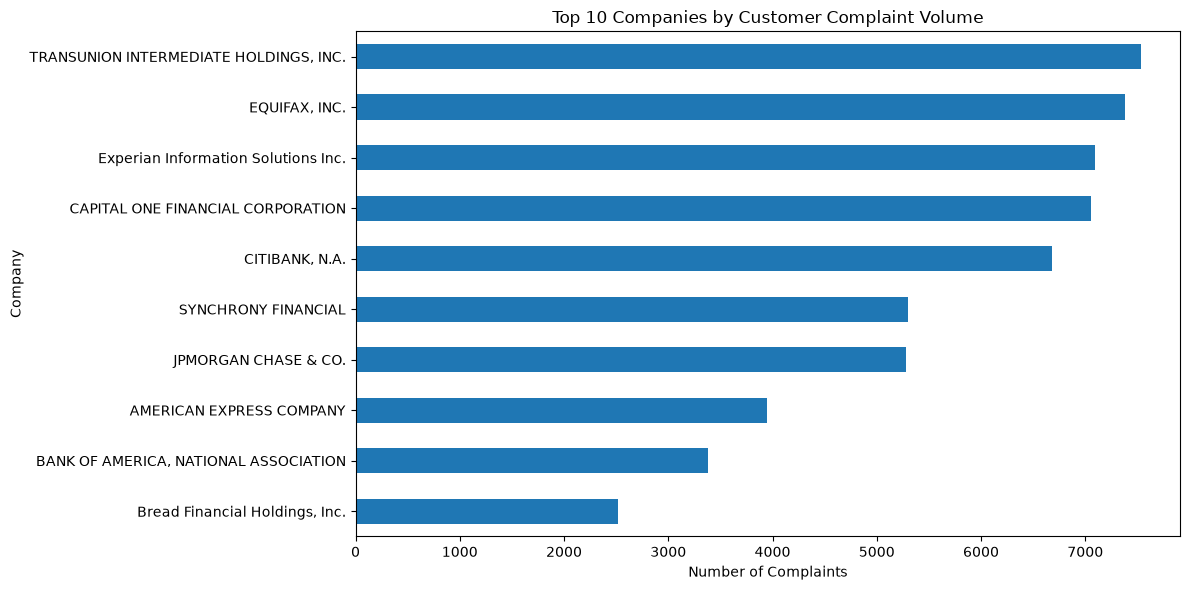

In [16]:
# Select the 10 companies with the most complaints
top_10_companies = df["Company"].value_counts().head(10)

# Create the bar chart
plt.figure(figsize=(12, 6))
top_10_companies.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Customer Complaint Volume")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")
plt.tight_layout()

plt.show()

In [7]:
df.shape

(75989, 15)

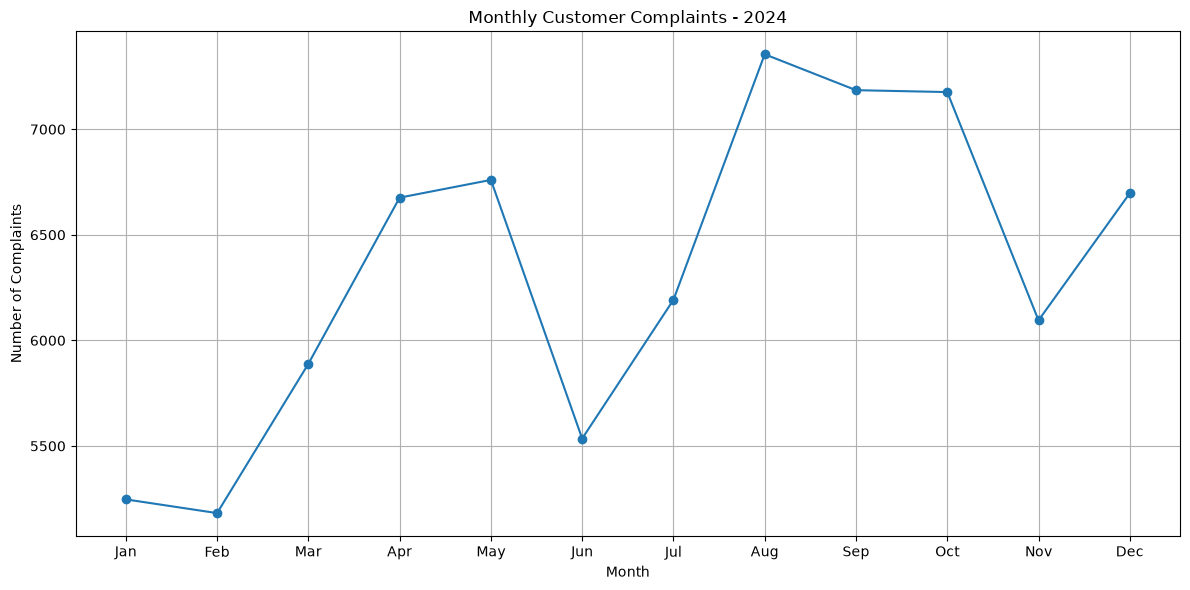

In [11]:
import matplotlib.pyplot as plt

# Count complaints by month
monthly_complaints = df.groupby(
    df["Date received"].dt.month
)["Complaint ID"].count()

# Create the line chart
plt.figure(figsize=(12, 6))
monthly_complaints.plot(kind="line", marker="o")

plt.title("Monthly Customer Complaints - 2024")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
df["Date received"] = pd.to_datetime(
    df["Date received"], errors="coerce", utc=True
).dt.tz_localize(None)

In [10]:
df["Date received"].dtype

dtype('<M8[us]')

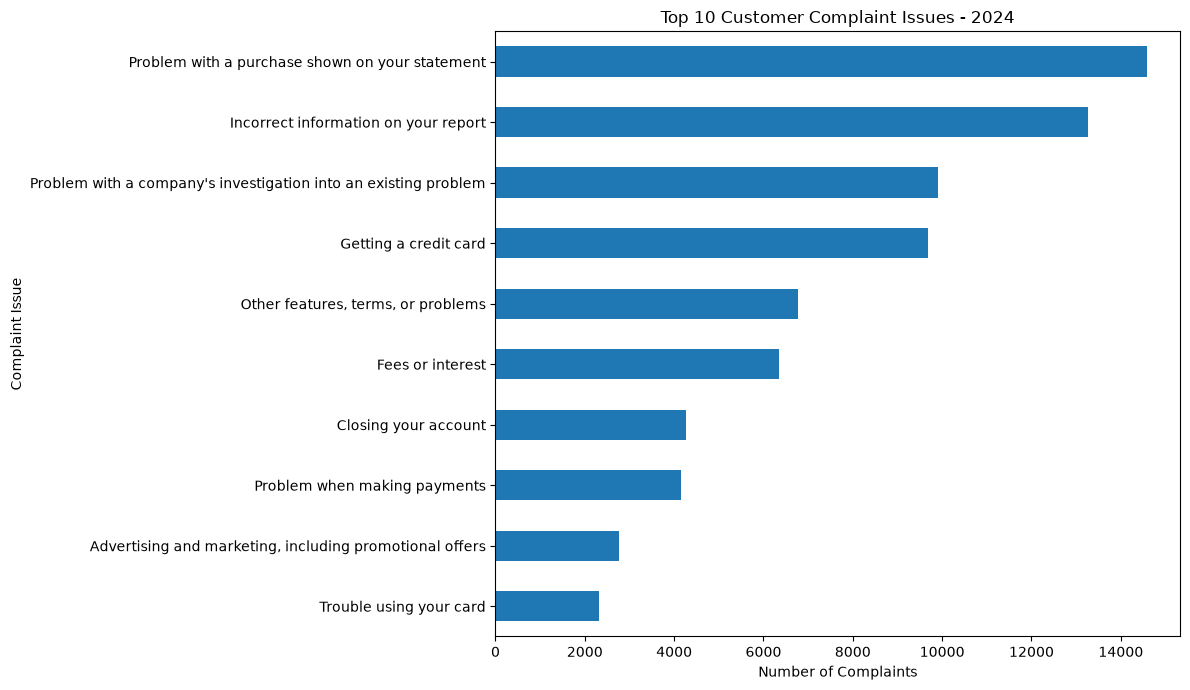

In [12]:
import matplotlib.pyplot as plt

# Find the 10 most common complaint issues
top_10_issues = df["Issue"].value_counts().head(10)

# Create the chart
plt.figure(figsize=(12, 7))
top_10_issues.sort_values().plot(kind="barh")

plt.title("Top 10 Customer Complaint Issues - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Issue")

plt.tight_layout()
plt.show()

In [13]:
# Count complaints by submission channel
submission_channels = df["Submitted via"].value_counts()

# Display the results
print(submission_channels)

Submitted via
Web            69852
Phone           2968
Referral        2477
Postal mail      692
Name: count, dtype: int64


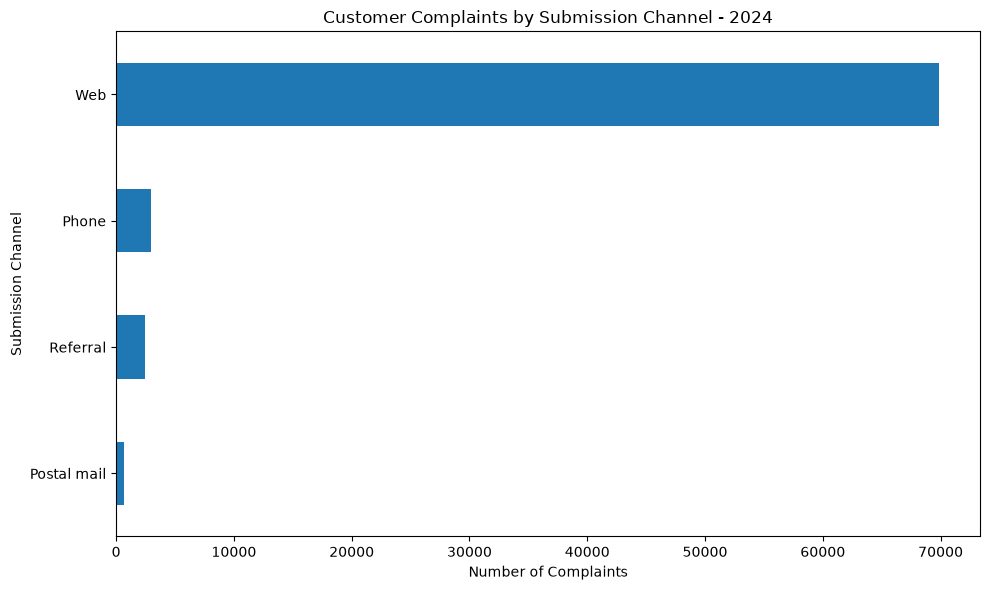

In [14]:
import matplotlib.pyplot as plt

submission_channels = df["Submitted via"].value_counts()

plt.figure(figsize=(10, 6))
submission_channels.sort_values().plot(kind="barh")

plt.title("Customer Complaints by Submission Channel - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Submission Channel")

plt.tight_layout()
plt.show()

In [15]:
# Count the different types of company responses to consumers
response_counts = df["Company response to consumer"].value_counts()

# Display the results
print(response_counts)

Company response to consumer
Closed with explanation            46317
Closed with non-monetary relief    19580
Closed with monetary relief        10067
Untimely response                     25
Name: count, dtype: int64


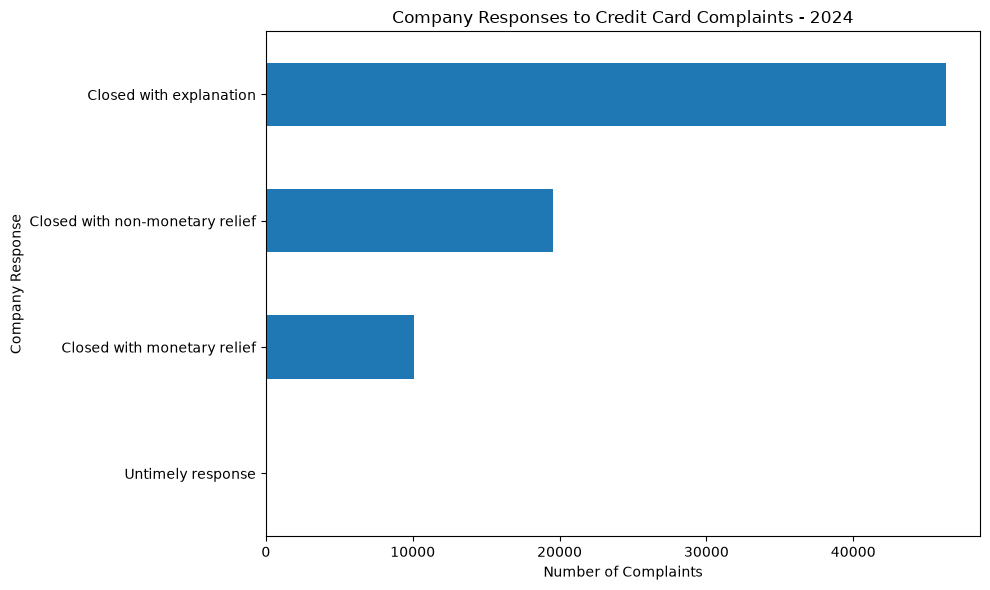

In [16]:
import matplotlib.pyplot as plt

response_counts = df["Company response to consumer"].value_counts()

plt.figure(figsize=(10, 6))
response_counts.sort_values().plot(kind="barh")

plt.title("Company Responses to Credit Card Complaints - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Company Response")

plt.tight_layout()
plt.show()

In [17]:
# Filter complaints that received monetary relief
monetary_relief = df[
    df["Company response to consumer"] == "Closed with monetary relief"
]

# Count the most common issues in these complaints
relief_by_issue = monetary_relief["Issue"].value_counts().head(10)

# Display the results
print(relief_by_issue)

Issue
Problem with a purchase shown on your statement                    4612
Fees or interest                                                   2272
Other features, terms, or problems                                 1043
Problem when making payments                                        907
Advertising and marketing, including promotional offers             392
Closing your account                                                351
Getting a credit card                                               155
Trouble using your card                                             130
Incorrect information on your report                                 78
Problem with a company's investigation into an existing problem      59
Name: count, dtype: int64


In [18]:
# Calculate total complaints and monetary-relief cases for each issue
issue_analysis = df.groupby("Issue").agg(
    Total_Complaints=("Complaint ID", "count"),
    Monetary_Relief_Cases=(
        "Company response to consumer",
        lambda x: (x == "Closed with monetary relief").sum()
    )
)

# Calculate the monetary-relief rate
issue_analysis["Monetary_Relief_Rate_%"] = (
    issue_analysis["Monetary_Relief_Cases"]
    / issue_analysis["Total_Complaints"] * 100
).round(2)

# Consider issues with at least 100 complaints
issue_analysis = issue_analysis[
    issue_analysis["Total_Complaints"] >= 100
]

# Display the 10 issues with the highest monetary-relief rates
top_relief_rates = issue_analysis.sort_values(
    "Monetary_Relief_Rate_%", ascending=False
).head(10)

print(top_relief_rates)

                                                    Total_Complaints  \
Issue                                                                  
Fees or interest                                                6343   
Problem with a purchase shown on your statement                14595   
Problem when making payments                                    4147   
Other features, terms, or problems                              6769   
Advertising and marketing, including promotiona...              2766   
Closing your account                                            4273   
Struggling to pay your bill                                      832   
Trouble using your card                                         2315   
Credit monitoring or identity theft protection ...               179   
Getting a credit card                                           9683   

                                                    Monetary_Relief_Cases  \
Issue                                                     

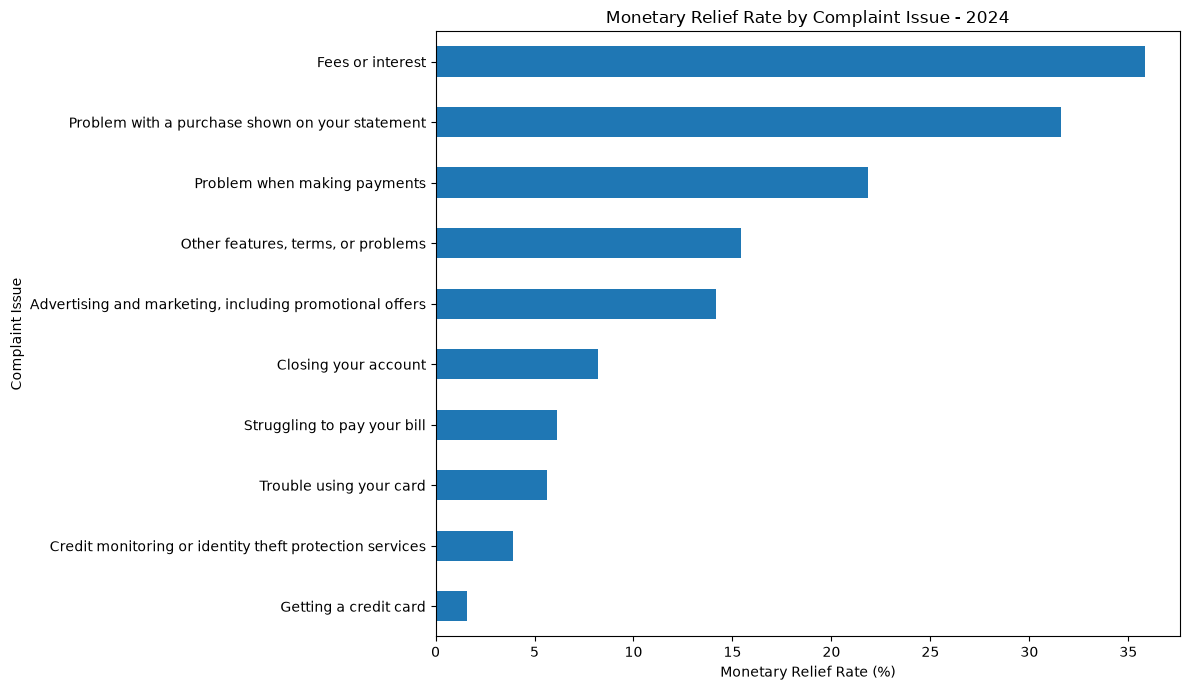

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

top_relief_rates["Monetary_Relief_Rate_%"].sort_values().plot(
    kind="barh"
)

plt.title("Monetary Relief Rate by Complaint Issue - 2024")
plt.xlabel("Monetary Relief Rate (%)")
plt.ylabel("Complaint Issue")

plt.tight_layout()
plt.show()

In [20]:
# Filter complaints related to fees or interest
fees_complaints = df[
    df["Issue"] == "Fees or interest"
]

# Count complaints by company
fees_by_company = fees_complaints["Company"].value_counts().head(10)

# Display the results
print(fees_by_company)

Company
SYNCHRONY FINANCIAL                      1146
CITIBANK, N.A.                            789
CAPITAL ONE FINANCIAL CORPORATION         776
Bread Financial Holdings, Inc.            751
AMERICAN EXPRESS COMPANY                  439
JPMORGAN CHASE & CO.                      329
BANK OF AMERICA, NATIONAL ASSOCIATION     283
WELLS FARGO & COMPANY                     180
BARCLAYS BANK DELAWARE                    167
DISCOVER BANK                             140
Name: count, dtype: int64


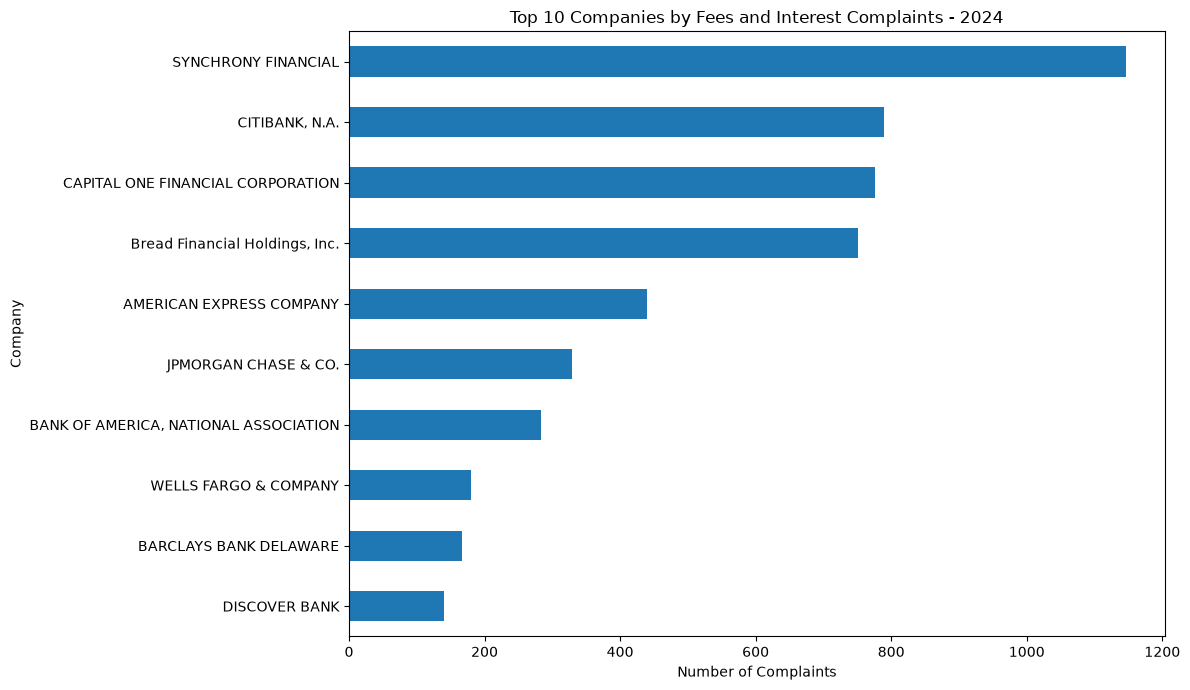

In [21]:
import matplotlib.pyplot as plt

fees_by_company = df[
    df["Issue"] == "Fees or interest"
]["Company"].value_counts().head(10)

plt.figure(figsize=(12, 7))

fees_by_company.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Fees and Interest Complaints - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

In [22]:
# Count complaints by state
state_complaints = df["State"].value_counts().head(10)

# Display the top 10 states
print(state_complaints)

State
TX    10172
CA     9301
FL     7416
NY     5220
IL     3926
GA     3474
PA     3258
NJ     2477
VA     2156
NC     2116
Name: count, dtype: int64


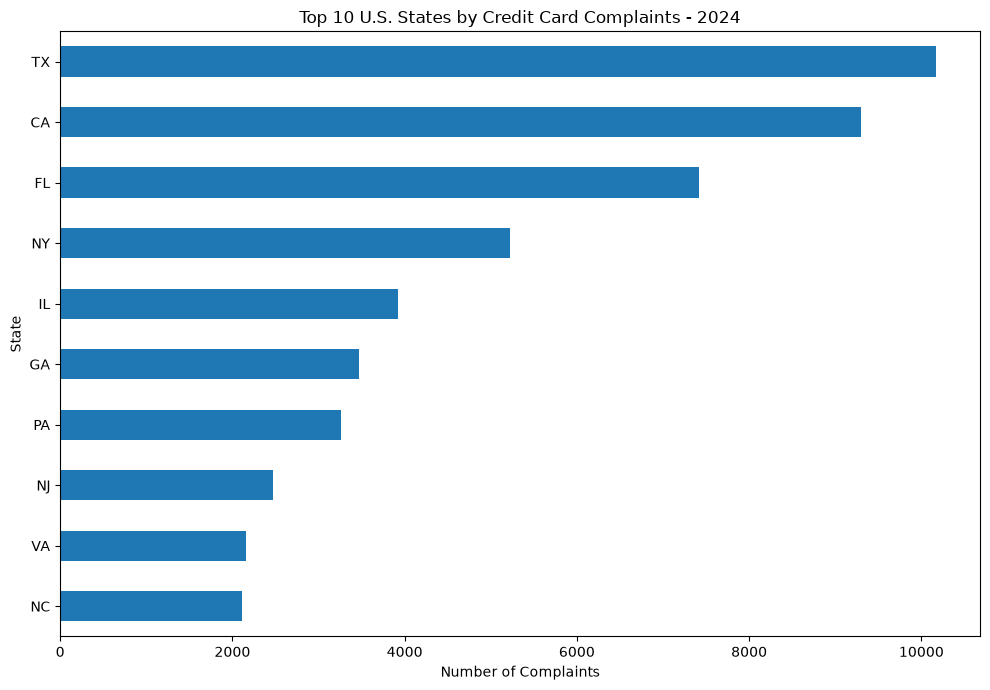

In [23]:
import matplotlib.pyplot as plt

state_complaints = df["State"].value_counts().head(10)

plt.figure(figsize=(10, 7))

state_complaints.sort_values().plot(kind="barh")

plt.title("Top 10 U.S. States by Credit Card Complaints - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [24]:
# Filter complaints closed without monetary relief
non_monetary = df[
    df["Company response to consumer"].isin([
        "Closed with explanation",
        "Closed with non-monetary relief"
    ])
]

# Count these complaints by company
non_monetary_by_company = (
    non_monetary["Company"].value_counts().head(10)
)

# Display the results
print(non_monetary_by_company)

Company
TRANSUNION INTERMEDIATE HOLDINGS, INC.    7532
EQUIFAX, INC.                             7382
Experian Information Solutions Inc.       7094
CAPITAL ONE FINANCIAL CORPORATION         6156
JPMORGAN CHASE & CO.                      4672
CITIBANK, N.A.                            4664
SYNCHRONY FINANCIAL                       4238
AMERICAN EXPRESS COMPANY                  3362
BANK OF AMERICA, NATIONAL ASSOCIATION     2160
DISCOVER BANK                             2118
Name: count, dtype: int64


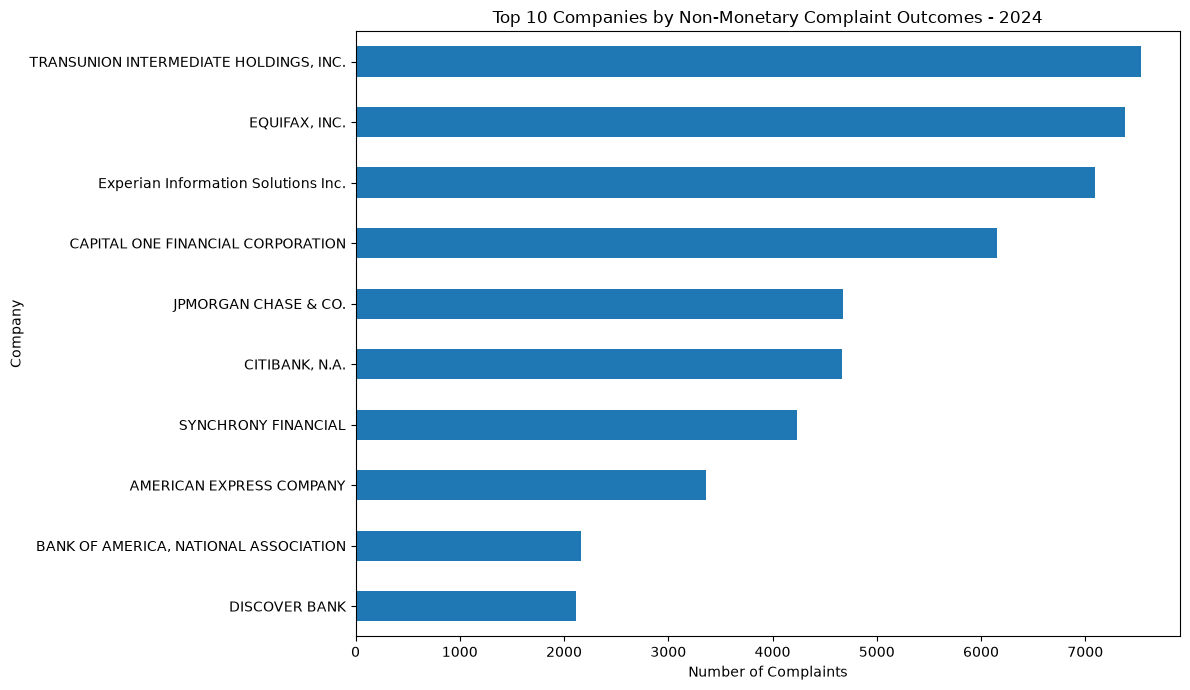

In [25]:
import matplotlib.pyplot as plt

non_monetary_by_company = (
    non_monetary["Company"].value_counts().head(10)
)

plt.figure(figsize=(12, 7))

non_monetary_by_company.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Non-Monetary Complaint Outcomes - 2024")
plt.xlabel("Number of Complaints")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

In [26]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Display columns containing missing values
print(missing_values[missing_values > 0].sort_values(ascending=False))

Tags                       65162
Company public response    37517
State                        213
Sub-issue                     63
dtype: int64


In [27]:
# Check for duplicate complaint IDs
duplicate_ids = df["Complaint ID"].duplicated().sum()

print("Duplicate complaint IDs:", duplicate_ids)

Duplicate complaint IDs: 0


In [28]:
clean_df = df.copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", clean_df.shape)

Original dataset: (75989, 15)
Cleaned dataset: (75989, 15)


In [29]:
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)

print(clean_df.columns.tolist())

['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response?', 'complaint_id']


In [30]:
clean_df.columns = (
    clean_df.columns
    .str.replace("?", "", regex=False)
    .str.replace("_+", "_", regex=True)
)

print(clean_df.columns.tolist())

['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'complaint_id']


In [31]:
print(clean_df.dtypes)

date_received                   datetime64[us]
product                                    str
sub_product                                str
issue                                      str
sub_issue                                  str
company_public_response                    str
company                                    str
state                                      str
zip_code                                   str
tags                                       str
submitted_via                              str
date_sent_to_company                       str
company_response_to_consumer               str
timely_response                            str
complaint_id                             int64
dtype: object


In [32]:
clean_df["date_sent_to_company"] = pd.to_datetime(
    clean_df["date_sent_to_company"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

print(clean_df["date_sent_to_company"].dtype)

datetime64[us]


In [33]:
print("Missing complaint dates:", clean_df["date_received"].isna().sum())

print("Missing company response dates:", clean_df["date_sent_to_company"].isna().sum())


Missing complaint dates: 0
Missing company response dates: 0


In [34]:
print("Timely response values:")
print(clean_df["timely_response"].value_counts(dropna=False))

print("\nCompany response values:")
print(clean_df["company_response_to_consumer"].value_counts(dropna=False))

Timely response values:
timely_response
Yes    75851
No       138
Name: count, dtype: int64

Company response values:
company_response_to_consumer
Closed with explanation            46317
Closed with non-monetary relief    19580
Closed with monetary relief        10067
Untimely response                     25
Name: count, dtype: int64


In [35]:
print("Missing issue values:", clean_df["issue"].isna().sum())

print("Number of unique complaint issues:", clean_df["issue"].nunique())

print("\nTop 10 complaint issues:")
print(clean_df["issue"].value_counts().head(10))

Missing issue values: 0
Number of unique complaint issues: 15

Top 10 complaint issues:
issue
Problem with a purchase shown on your statement                    14595
Incorrect information on your report                               13261
Problem with a company's investigation into an existing problem     9911
Getting a credit card                                               9683
Other features, terms, or problems                                  6769
Fees or interest                                                    6343
Closing your account                                                4273
Problem when making payments                                        4147
Advertising and marketing, including promotional offers             2766
Trouble using your card                                             2315
Name: count, dtype: int64


In [36]:
print("Missing company names:", clean_df["company"].isna().sum())

print("Number of unique companies:", clean_df["company"].nunique())

print("\nTop 10 companies by complaint volume:")
print(clean_df["company"].value_counts().head(10))

Missing company names: 0
Number of unique companies: 459

Top 10 companies by complaint volume:
company
TRANSUNION INTERMEDIATE HOLDINGS, INC.    7532
EQUIFAX, INC.                             7382
Experian Information Solutions Inc.       7097
CAPITAL ONE FINANCIAL CORPORATION         7058
CITIBANK, N.A.                            6685
SYNCHRONY FINANCIAL                       5301
JPMORGAN CHASE & CO.                      5276
AMERICAN EXPRESS COMPANY                  3950
BANK OF AMERICA, NATIONAL ASSOCIATION     3381
Bread Financial Holdings, Inc.            2515
Name: count, dtype: int64


In [37]:
print("Missing state values:", clean_df["state"].isna().sum())

print("Number of unique states:", clean_df["state"].nunique())

print("\nTop 10 states by complaint volume:")
print(clean_df["state"].value_counts().head(10))

Missing state values: 213
Number of unique states: 59

Top 10 states by complaint volume:
state
TX    10172
CA     9301
FL     7416
NY     5220
IL     3926
GA     3474
PA     3258
NJ     2477
VA     2156
NC     2116
Name: count, dtype: int64


In [38]:
print("Missing submission channels:", clean_df["submitted_via"].isna().sum())

print("Number of unique submission channels:", clean_df["submitted_via"].nunique())

print("\nComplaints by submission channel:")
print(clean_df["submitted_via"].value_counts())

Missing submission channels: 0
Number of unique submission channels: 4

Complaints by submission channel:
submitted_via
Web            69852
Phone           2968
Referral        2477
Postal mail      692
Name: count, dtype: int64


In [39]:
print("Product categories:")
print(clean_df["product"].value_counts())

print("\nNumber of unique products:", clean_df["product"].nunique())

Product categories:
product
Credit card    75989
Name: count, dtype: int64

Number of unique products: 1


In [40]:
print("Missing complaint IDs:", clean_df["complaint_id"].isna().sum())

print("Duplicate complaint IDs:", clean_df["complaint_id"].duplicated().sum())

print("Unique complaint IDs:", clean_df["complaint_id"].nunique())

Missing complaint IDs: 0
Duplicate complaint IDs: 0
Unique complaint IDs: 75989


In [41]:
print("Earliest complaint date:", clean_df["date_received"].min())

print("Latest complaint date:", clean_df["date_received"].max())

Earliest complaint date: 2024-01-01 00:04:58
Latest complaint date: 2024-12-31 23:36:19


In [42]:
print("Final dataset rows:", clean_df.shape[0])
print("Final dataset columns:", clean_df.shape[1])
print("Total missing values:", clean_df.isna().sum().sum())

Final dataset rows: 75989
Final dataset columns: 15
Total missing values: 102955


In [43]:
missing_summary = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (
        clean_df.isna().sum() / len(clean_df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percentage", ascending=False)

print(missing_summary)

                         Missing_Count  Missing_Percentage
tags                             65162               85.75
company_public_response          37517               49.37
state                              213                0.28
sub_issue                           63                0.08


In [44]:
clean_df["month"] = clean_df["date_received"].dt.month_name()

print(clean_df[["date_received", "month"]].head())

        date_received    month
0 2024-01-01 01:53:02  January
1 2024-01-01 06:23:49  January
2 2024-01-01 13:57:28  January
3 2024-01-01 15:48:58  January
4 2024-01-01 16:29:32  January


In [45]:
clean_df["month_number"] = clean_df["date_received"].dt.month

print(
    clean_df[["date_received", "month", "month_number"]].head()
)

        date_received    month  month_number
0 2024-01-01 01:53:02  January             1
1 2024-01-01 06:23:49  January             1
2 2024-01-01 13:57:28  January             1
3 2024-01-01 15:48:58  January             1
4 2024-01-01 16:29:32  January             1


In [46]:
clean_df["year"] = clean_df["date_received"].dt.year

print(clean_df[["date_received", "month", "month_number", "year"]].head())

        date_received    month  month_number  year
0 2024-01-01 01:53:02  January             1  2024
1 2024-01-01 06:23:49  January             1  2024
2 2024-01-01 13:57:28  January             1  2024
3 2024-01-01 15:48:58  January             1  2024
4 2024-01-01 16:29:32  January             1  2024


In [47]:
print("Dataset shape:", clean_df.shape)

print("\nNew columns:")
print(clean_df[["month", "month_number", "year"]].head())

print("\nYears in dataset:")
print(clean_df["year"].value_counts())

Dataset shape: (75989, 18)

New columns:
     month  month_number  year
0  January             1  2024
1  January             1  2024
2  January             1  2024
3  January             1  2024
4  January             1  2024

Years in dataset:
year
2024    75989
Name: count, dtype: int64


In [48]:
print(clean_df.columns.tolist())

['date_received', 'product', 'sub_product', 'issue', 'sub_issue', 'company_public_response', 'company', 'state', 'zip_code', 'tags', 'submitted_via', 'date_sent_to_company', 'company_response_to_consumer', 'timely_response', 'complaint_id', 'month', 'month_number', 'year']


In [49]:
print("Duplicate rows:", clean_df.duplicated().sum())

print("Duplicate complaint IDs:", clean_df["complaint_id"].duplicated().sum())

Duplicate rows: 0
Duplicate complaint IDs: 0


In [50]:
columns_to_check = [
    "issue",
    "company",
    "state",
    "submitted_via",
    "company_response_to_consumer",
    "timely_response"
]

for col in columns_to_check:
    print(f"\n{col}:")
    print(clean_df[col].nunique())


issue:
15

company:
459

state:
59

submitted_via:
4

company_response_to_consumer:
4

timely_response:
2


In [51]:
clean_df.to_csv("cleaned_credit_card_complaints.csv", index=False)

In [52]:
import os
print(os.getcwd())

C:\Users\nnpat
